# Motif mix along one-minute windows

Eight motifs from `SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_gap01` (dictionary 24). A placement is counted in the minute where it starts. The recording clock is the GPL window start plus `t_start` times the hop (24576 / 200000 s). The file is 37.5 minutes, so minute 37 covers only the last 30 seconds.

Motif ids are 0, 1, 10, 11, 13, 14, 17, and 44.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.limited_overlap_m8x32_refine2_gap01"
)
GPL = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "SOCAL_H_76_230427_014845.x.gpl/output/spectrogram_npy"
)
summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
motif_ids = [int(row["motif_id"]) for row in summary["motifs"]]
index = {motif_id: i for i, motif_id in enumerate(motif_ids)}

metas = {path.stem: json.loads(path.read_text()) for path in GPL.glob("*.json")}
duration = max(meta["end_sample"] / meta["sample_freq"] for meta in metas.values())
minute = 60.0
n_minutes = int(np.ceil(duration / minute))

starts = np.empty(len(matchings))
widths = np.empty(len(matchings))
owners = np.empty(len(matchings), dtype=int)
for i, row in enumerate(matchings):
    meta = metas[row["window_id"]]
    hop = meta["overlap"] / meta["sample_freq"]
    starts[i] = (meta["start_sample"] - 1) / meta["sample_freq"] + row["t_start"] * hop
    widths[i] = row["width"] * hop
    owners[i] = index[int(row["motif_id"])]

bins = np.minimum((starts / minute).astype(int), n_minutes - 1)
counts = np.zeros((len(motif_ids), n_minutes), dtype=int)
for motif_i, minute_i in zip(owners, bins):
    counts[motif_i, minute_i] += 1
per_minute = counts.sum(axis=0)
share = np.divide(counts, per_minute, out=np.full_like(counts, np.nan, dtype=float), where=per_minute > 0)
overall = counts.sum(axis=1) / counts.sum()
crosses = int(np.sum(np.floor((starts + widths) / minute) != np.floor(starts / minute)))

print(
    f"placements {len(matchings)}  motifs {len(motif_ids)}  "
    f"duration {duration / 60:.2f} min  windows {n_minutes}"
)
print(f"placements that cross a minute boundary: {crosses}")
print(f"occupied minutes {(per_minute > 0).sum()} of {n_minutes}")
print("minute   n    " + "  ".join(f"{motif_id:4d}" for motif_id in motif_ids) + "   lead")
for minute_i in range(n_minutes):
    row = "  ".join(f"{counts[j, minute_i]:4d}" for j in range(len(motif_ids)))
    if per_minute[minute_i] == 0:
        lead = "  -"
    else:
        winner = int(np.argmax(counts[:, minute_i]))
        lead = f"{motif_ids[winner]:3d}  {counts[winner, minute_i] / per_minute[minute_i]:.0%}"
    label = f"{minute_i:2d}" if minute_i < n_minutes - 1 else f"{minute_i:2d}*"
    print(f"{label}    {per_minute[minute_i]:3d}   {row}   {lead}")
print("* minute 37 is 30 seconds")


placements 166  motifs 8  duration 37.50 min  windows 38
placements that cross a minute boundary: 4
occupied minutes 22 of 38
minute   n       0     1    10    11    13    14    17    44   lead
 0     11      2     6     2     0     1     0     0     0     1  55%
 1      8      1     1     4     1     1     0     0     0    10  50%
 2      0      0     0     0     0     0     0     0     0     -
 3      0      0     0     0     0     0     0     0     0     -
 4      0      0     0     0     0     0     0     0     0     -
 5      0      0     0     0     0     0     0     0     0     -
 6      0      0     0     0     0     0     0     0     0     -
 7      0      0     0     0     0     0     0     0     0     -
 8     10      2     0     0     1     0     3     2     2    14  30%
 9     10      2     3     0     1     0     1     3     0     1  30%
10     10      0     3     0     0     0     1     6     0    17  60%
11      9      0     4     0     0     0     0     5     0    17  

## Counts and mix

Each column is one minute. The first heatmap is the number of placements. The second is that minute's mix: each column sums to 1, and an empty minute is left blank. Colors in the stacked bars match the motif order in the legend.


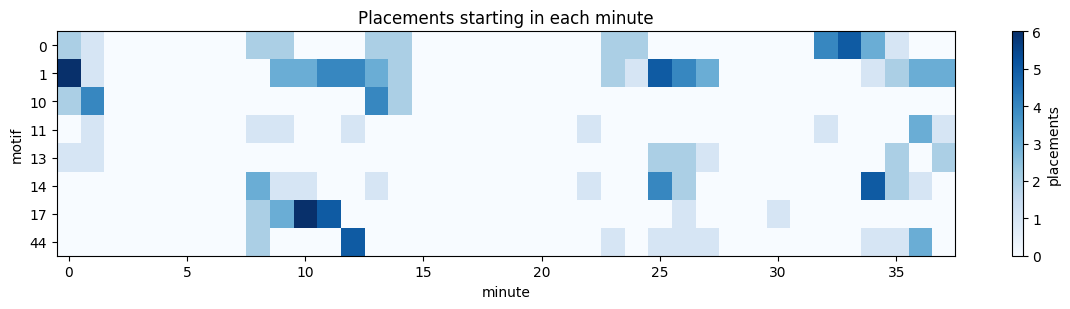

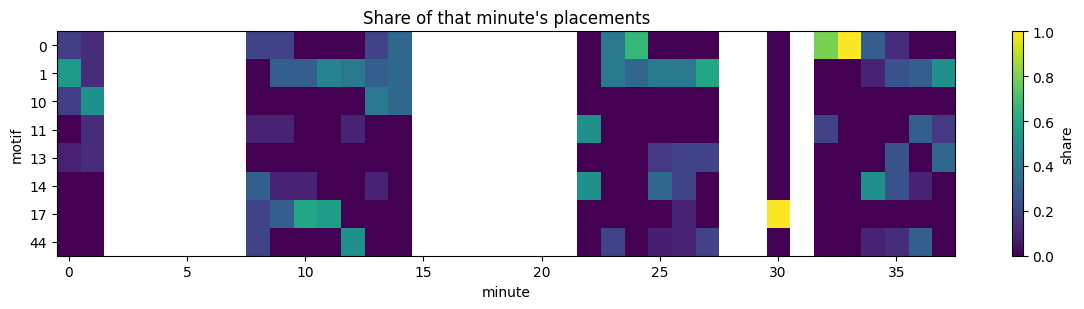

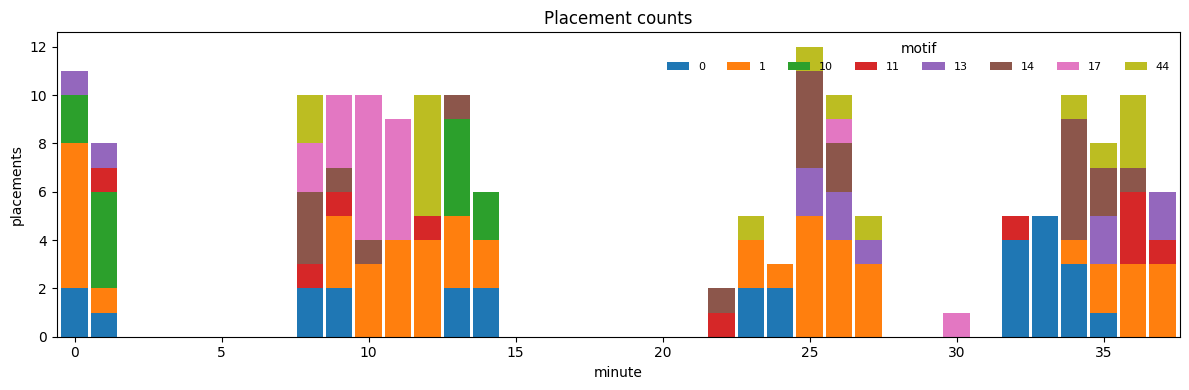

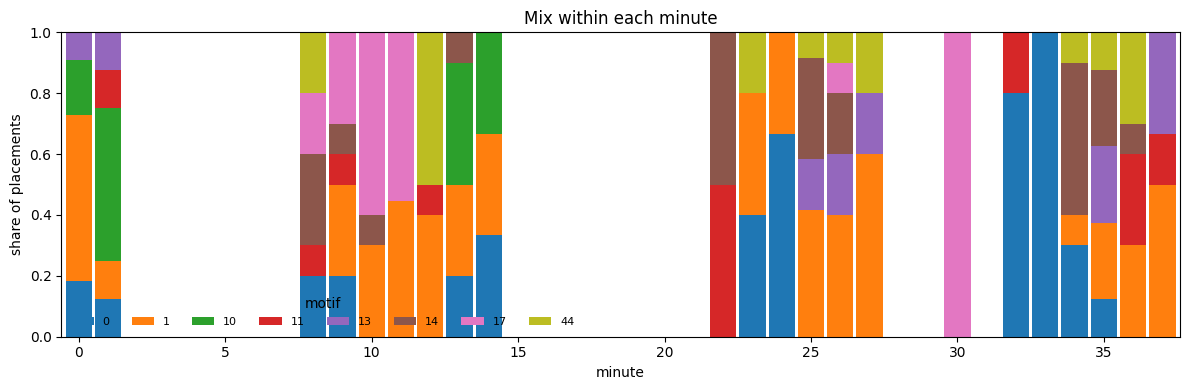

In [2]:
colors = plt.cm.tab10(np.linspace(0, 0.8, len(motif_ids)))

fig, ax = plt.subplots(figsize=(12, 3.2))
image = ax.imshow(counts, origin="upper", aspect="auto", cmap="Blues", interpolation="nearest")
ax.set_yticks(np.arange(len(motif_ids)))
ax.set_yticklabels(motif_ids)
ax.set_xlabel("minute")
ax.set_ylabel("motif")
ax.set_title("Placements starting in each minute")
fig.colorbar(image, ax=ax, label="placements")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(12, 3.2))
mix = np.ma.masked_invalid(share)
image = ax.imshow(mix, origin="upper", aspect="auto", cmap="viridis", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(np.arange(len(motif_ids)))
ax.set_yticklabels(motif_ids)
ax.set_xlabel("minute")
ax.set_ylabel("motif")
ax.set_title("Share of that minute's placements")
fig.colorbar(image, ax=ax, label="share")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(n_minutes)
for j, motif_id in enumerate(motif_ids):
    ax.bar(np.arange(n_minutes), counts[j], bottom=bottom, width=0.9, color=colors[j], label=str(motif_id))
    bottom += counts[j]
ax.set_xlabel("minute")
ax.set_ylabel("placements")
ax.set_xlim(-0.6, n_minutes - 0.4)
ax.set_title("Placement counts")
ax.legend(title="motif", ncol=8, fontsize=8, frameon=False)
fig.tight_layout()

fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(n_minutes)
for j, motif_id in enumerate(motif_ids):
    height = np.nan_to_num(share[j])
    ax.bar(np.arange(n_minutes), height, bottom=bottom, width=0.9, color=colors[j], label=str(motif_id))
    bottom += height
ax.set_xlabel("minute")
ax.set_ylabel("share of placements")
ax.set_xlim(-0.6, n_minutes - 0.4)
ax.set_ylim(0, 1)
ax.set_title("Mix within each minute")
ax.legend(title="motif", ncol=8, fontsize=8, frameon=False)
fig.tight_layout()


## Where each motif sits

The shortest interval that holds 80% of a motif's own placements. A short interval means the motif is concentrated in one part of the recording. The distance column is half the L1 distance between that minute's mix and the mix over the whole recording, so 0 is the average mix and 1 is a completely different mix.


In [3]:
print("motif   n   80% of placements")
for j, motif_id in enumerate(motif_ids):
    times = np.sort(starts[owners == j])
    need = int(np.ceil(0.8 * len(times)))
    best = None
    for i in range(len(times) - need + 1):
        span = times[i + need - 1] - times[i]
        if best is None or span < best[0]:
            best = (span, times[i], times[i + need - 1])
    print(
        f"{motif_id:5d}  {len(times):3d}   "
        f"{best[1] / 60:5.2f}–{best[2] / 60:5.2f} min   ({best[0] / 60:4.1f} min)"
    )

print()
print("minute   n   distance from the recording mix   lead")
for minute_i in range(n_minutes):
    if per_minute[minute_i] == 0:
        continue
    distance = 0.5 * np.nansum(np.abs(share[:, minute_i] - overall))
    winner = int(np.argmax(counts[:, minute_i]))
    print(
        f"{minute_i:6d}  {per_minute[minute_i]:3d}   {distance:5.2f}   "
        f"motif {motif_ids[winner]}  {counts[winner, minute_i] / per_minute[minute_i]:.0%}"
    )


motif   n   80% of placements
    0   28    8.87–34.48 min   (25.6 min)
    1   50   10.08–37.41 min   (27.3 min)
   10   12    0.67–13.95 min   (13.3 min)
   11   10    9.68–37.03 min   (27.3 min)
   13   11   25.78–37.34 min   (11.6 min)
   14   21   10.85–36.20 min   (25.4 min)
   17   18    8.99–11.93 min   ( 2.9 min)
   44   16   12.42–36.78 min   (24.4 min)

minute   n   distance from the recording mix   lead
     0   11    0.39   motif 1  55%
     1    8    0.55   motif 10  50%
     8   10    0.44   motif 14  30%
     9   10    0.26   motif 1  30%
    10   10    0.49   motif 17  60%
    11    9    0.59   motif 17  56%
    12   10    0.54   motif 44  50%
    13   10    0.36   motif 10  40%
    14    6    0.46   motif 0  33%
    22    2    0.81   motif 11  50%
    23    5    0.43   motif 0  40%
    24    3    0.53   motif 0  67%
    25   12    0.42   motif 1  42%
    26   10    0.31   motif 1  40%
    27    5    0.54   motif 1  60%
    30    1    0.89   motif 17  100%
    32    5 

## Reading

Placements occupy 22 of the 38 minutes. The quiet stretches are minutes 2–7, 15–21, 28–29, and 31.

Motif 1 is the motif that keeps returning: it leads minutes 0, 9, 25–27, and 35–37. Motif 17 is the opposite. Sixteen of its 18 placements start in minutes 8–11, and it leads minutes 10 and 11. Motif 10 is an opening motif: all 12 placements start before minute 15, and it leads minutes 1 and 13. Motif 0 takes the recording over at minutes 32 and 33 (9 of its 28 placements, 80% and 100% of those minutes). Motif 13 arrives late: 9 of its 11 placements start after minute 25. Motif 14 has two bursts, minutes 8–10 and minutes 25–26 plus 34–35. Motif 44 peaks in minute 12 (5 of 16). Motif 11 stays sparse until minutes 36–37, which hold 4 of its 10 placements.
